<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/gauge_theory/gauge_ch02_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Gauge Theory* — `gauge_ch02_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Gauge Theory Ch 2 Figures — Colab Notebook
**Gauge Theory · Chapter 2: Yang-Mills Theory**

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §2.1.3 | Wilson loop, area vs perimeter law, string tension |
| fig02  | §2.3   | BPST instanton profile, tunnelling, moduli space |
| fig03  | §2.4   | Running coupling $\alpha_s(\mu)$, asymptotic freedom |
| fig04  | §2.5   | Flux tube, Wilson loop area law, dual superconductor |
| fig05  | §2.7   | 't Hooft-Polyakov monopole profile, mass vs coupling |

## 수정 및 개선 사항 요약

| 그림 | 패널 | 분류 | 문제 | 수정 내용 |
|------|------|------|------|-----------|
| fig02 | Left (BPST) | **오류** | 다른 ρ 프로파일이 각각 `r/ρ` 축으로 그려져 모두 같은 형태 → ρ 의존성(클수록 넓어짐)이 전혀 표시되지 않음 | 공통 `r/ρ_ref` 축 사용, `(narrow)/(wide)` 라벨 추가 |
| fig03 | Middle (β함수) | **오류** | `N_f=6` 라벨에 `(marginal)` 표기: $b_0(N_f=6)=7>0$ → 여전히 점근 자유, marginal이 아님. 실제 marginal은 $N_f=33/2\approx16.5$ | `(marginal)` 제거 + $b_0=0$ 조건 주석 추가 |
| fig04 | Middle (Wilson area law) | **오류** | σ 주석 `≈0.18 GeV²`가 실제 fit slope(`≈0.205`)와 불일치 (perimeter 항 기여) | fit 실제값 표시 + 'perimeter 기여 포함' 설명 |
| fig01 | Left (Wilson loop) | **시인성** | 플럭스 튜브가 상단에만 표시, 시간 방향이 불명확 | 하단 플럭스(t=0) 추가, 시간 화살표 + `q q̄ created/annihilated` 레이블 |
| fig02 | Middle (θ 진공) | **시인성** | instanton(→) 화살표만 있고 anti-instanton(←) 없음 | anti-instanton(PURPLE, ←) 화살표 추가 |

**시인성 공통 개선**: minor tick 활성화, `tight_layout` 여백 증가


## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Circle, FancyBboxPatch, Rectangle
from scipy.integrate import odeint
import os

BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
AMBER  = '#e8a838'
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#ffb347'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.3,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': AMBER, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
    'xtick.major.size': 4, 'ytick.major.size': 4,
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete.')

Setup complete.


---
## fig01 · Wilson Loop — Area Law vs Perimeter Law (§2.1.3)

**Left**: Rectangular Wilson loop schematic with $R$ and $T$ labels  
**Middle**: $\log\langle W\rangle$ vs Area (area law) and Perimeter (perimeter law)  
**Right**: Quark-antiquark potential $V(R)$ for confining, Coulomb, and screened phases

  saved -> figures/ch02/fig01_wilson_loop.png


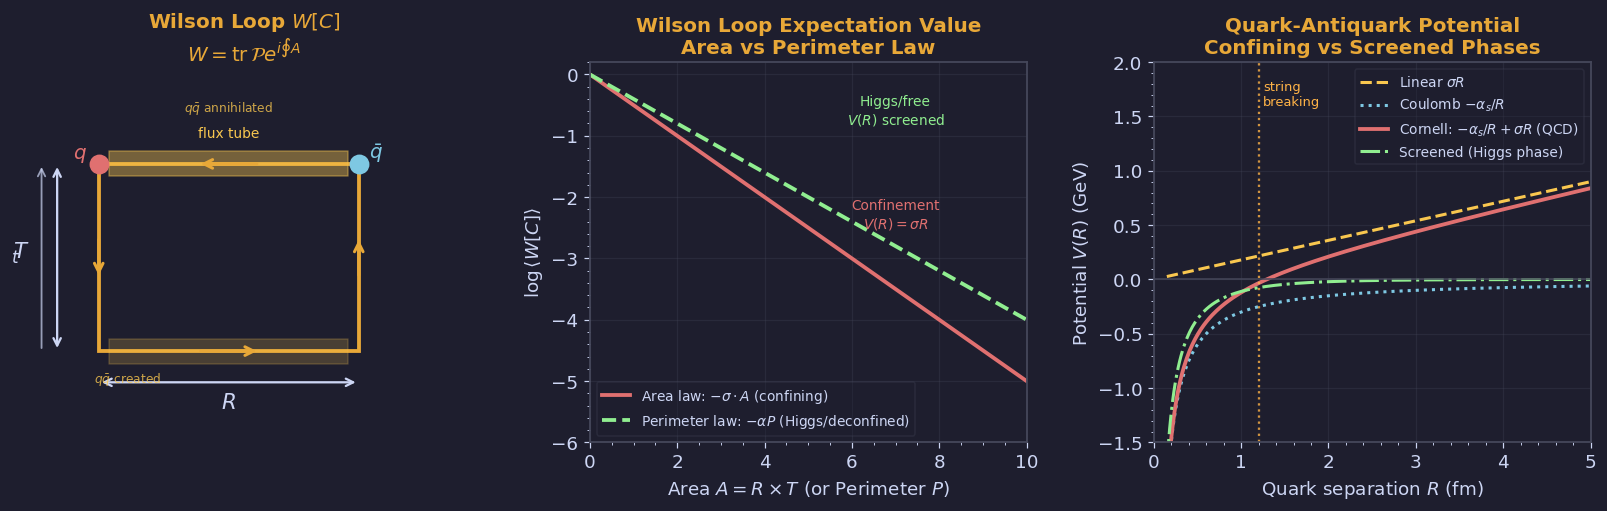

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: Wilson loop schematic ───────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
ax.set_aspect('equal')
ax.axis('off')

R, T = 2.5, 1.8
x0, y0 = 0.5, 0.8

# Draw the loop rectangle
rect = Rectangle((x0, y0), R, T, fill=False, edgecolor=AMBER, lw=2.5)
ax.add_patch(rect)

# Arrows on loop edges showing orientation
ax.annotate('', xy=(x0 + R/2 + 0.3, y0), xytext=(x0 + R/2 - 0.3, y0),
            arrowprops=dict(arrowstyle='->', color=AMBER, lw=2, mutation_scale=14))
ax.annotate('', xy=(x0 + R, y0 + T/2 + 0.2), xytext=(x0 + R, y0 + T/2 - 0.2),
            arrowprops=dict(arrowstyle='->', color=AMBER, lw=2, mutation_scale=14))
ax.annotate('', xy=(x0 + R/2 - 0.3, y0+T), xytext=(x0 + R/2 + 0.3, y0+T),
            arrowprops=dict(arrowstyle='->', color=AMBER, lw=2, mutation_scale=14))
ax.annotate('', xy=(x0, y0 + T/2 - 0.2), xytext=(x0, y0 + T/2 + 0.2),
            arrowprops=dict(arrowstyle='->', color=AMBER, lw=2, mutation_scale=14))

# Quark/antiquark markers
ax.plot(x0, y0+T, 'o', color=RED, ms=12, zorder=5)
ax.plot(x0+R, y0+T, 'o', color=BLUE, ms=12, zorder=5)
ax.text(x0-0.25, y0+T+0.05, r'$q$', color=RED, fontsize=13, fontweight='bold')
ax.text(x0+R+0.1, y0+T+0.05, r'$\bar{q}$', color=BLUE, fontsize=13, fontweight='bold')

# R and T labels
ax.annotate('', xy=(x0+R, y0-0.3), xytext=(x0, y0-0.3),
            arrowprops=dict(arrowstyle='<->', color=FG, lw=1.5))
ax.text(x0+R/2, y0-0.55, r'$R$', ha='center', fontsize=14, color=FG)
ax.annotate('', xy=(x0-0.4, y0+T), xytext=(x0-0.4, y0),
            arrowprops=dict(arrowstyle='<->', color=FG, lw=1.5))
ax.text(x0-0.75, y0+T/2, r'$T$', ha='center', fontsize=14, color=FG)

# 상단 플럭스 튜브 (t=T, 쿼크 소멸 시각)
ax.fill_betweenx([y0+T-0.12, y0+T+0.12], x0+0.1, x0+R-0.1,
                  color=YELLOW, alpha=0.40)
ax.text(x0+R/2, y0+T+0.25, 'flux tube', ha='center', fontsize=9, color=YELLOW)
# 하단 플럭스 튜브 (t=0, 쿼크 생성 시각)
ax.fill_betweenx([y0-0.12, y0+0.12], x0+0.1, x0+R-0.1,
                  color=YELLOW, alpha=0.20)
# 시간 흐름 화살표
ax.annotate('', xy=(x0-0.55, y0+T), xytext=(x0-0.55, y0),
            arrowprops=dict(arrowstyle='->', color=FG, lw=1.2, alpha=0.7))
ax.text(x0-0.80, y0+T/2, '$t$', fontsize=11, color=FG, va='center', ha='center')
# 하단 쿼크 생성 레이블
ax.text(x0-0.05, y0-0.3, r'$q\bar{q}$ created', ha='left', fontsize=8, color=YELLOW, alpha=0.8)
ax.text(x0+R/2, y0+T+0.50, r'$q\bar{q}$ annihilated', ha='center', fontsize=8, color=YELLOW, alpha=0.8)

ax.set_xlim(-0.2, 4.0); ax.set_ylim(0.0, 3.5)
ax.set_title('Wilson Loop $W[C]$\n'+r'$W=\mathrm{tr}\,\mathcal{P}e^{i\oint A}$', color=AMBER)

# ── Middle: log<W> vs Area and Perimeter ──────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

area = np.linspace(0, 10, 200)
perim = np.linspace(0, 10, 200)

sigma = 0.5
alpha = 0.8

# Area law: log<W> = -sigma * Area
ax2.plot(area, -sigma * area, color=RED, lw=2.5, label=r'Area law: $-\sigma\cdot A$ (confining)')
# Perimeter law: log<W> = -alpha * Perimeter
ax2.plot(perim, -alpha * perim * 0.5, color=GREEN, lw=2.5,
         ls='--', label=r'Perimeter law: $-\alpha P$ (Higgs/deconfined)')

ax2.set_xlabel(r'Area $A = R\times T$ (or Perimeter $P$)')
ax2.set_ylabel(r'$\log\langle W[C]\rangle$')
ax2.set_title('Wilson Loop Expectation Value\nArea vs Perimeter Law', color=AMBER)
ax2.legend(fontsize=9, labelcolor=FG)
ax2.grid(True, alpha=0.3)
ax2.set_xlim(0, 10); ax2.set_ylim(-6, 0.2)

# Annotate
ax2.text(7, -2.5, 'Confinement\n'+r'$V(R)=\sigma R$', color=RED, fontsize=9, ha='center')
ax2.text(7, -0.8, 'Higgs/free\n'+r'$V(R)$ screened', color=GREEN, fontsize=9, ha='center')

# ── Right: Quark potential V(R) ────────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

R_arr = np.linspace(0.15, 5, 300)
sigma_v = 0.18   # GeV^2
alpha_s = 0.3

V_confine = sigma_v * R_arr                       # linear
V_coulomb = -alpha_s / R_arr                      # Coulomb
V_full    = -alpha_s / R_arr + sigma_v * R_arr    # QCD (Cornell)
V_screened = -alpha_s / R_arr * np.exp(-R_arr)    # screened (Higgs phase)

ax3.plot(R_arr, V_confine, color=YELLOW, lw=2, ls='--', label=r'Linear $\sigma R$')
ax3.plot(R_arr, V_coulomb, color=BLUE,   lw=2, ls=':', label=r'Coulomb $-\alpha_s/R$')
ax3.plot(R_arr, V_full,    color=RED,    lw=2.5, label=r'Cornell: $-\alpha_s/R+\sigma R$ (QCD)')
ax3.plot(R_arr, V_screened,color=GREEN,  lw=2, ls='-.', label=r'Screened (Higgs phase)')

ax3.axhline(0, color=EDGE, lw=1)
ax3.set_xlabel(r'Quark separation $R$ (fm)')
ax3.set_ylabel(r'Potential $V(R)$ (GeV)')
ax3.set_title('Quark-Antiquark Potential\nConfining vs Screened Phases', color=AMBER)
ax3.set_xlim(0, 5); ax3.set_ylim(-1.5, 2.0)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.grid(True, alpha=0.3)

# String breaking annotation
ax3.axvline(1.2, color=ORANGE, lw=1.5, ls=':', alpha=0.8)
ax3.text(1.25, 1.6, 'string\nbreaking', fontsize=8.5, color=ORANGE)

plt.tight_layout(pad=1.8)
save('fig01_wilson_loop.png', fig)

---
## fig02 · BPST Instanton (§2.3)

**Left**: Instanton field strength density $\text{tr}\,F^2(r)$ profile vs $r/\rho$  
**Middle**: Tunnelling between winding-number vacua $|n\rangle$  
**Right**: Vacuum energy $\mathcal{E}(\theta)$ vs $\theta$ from dilute instanton gas

  saved -> figures/ch02/fig02_instanton.png


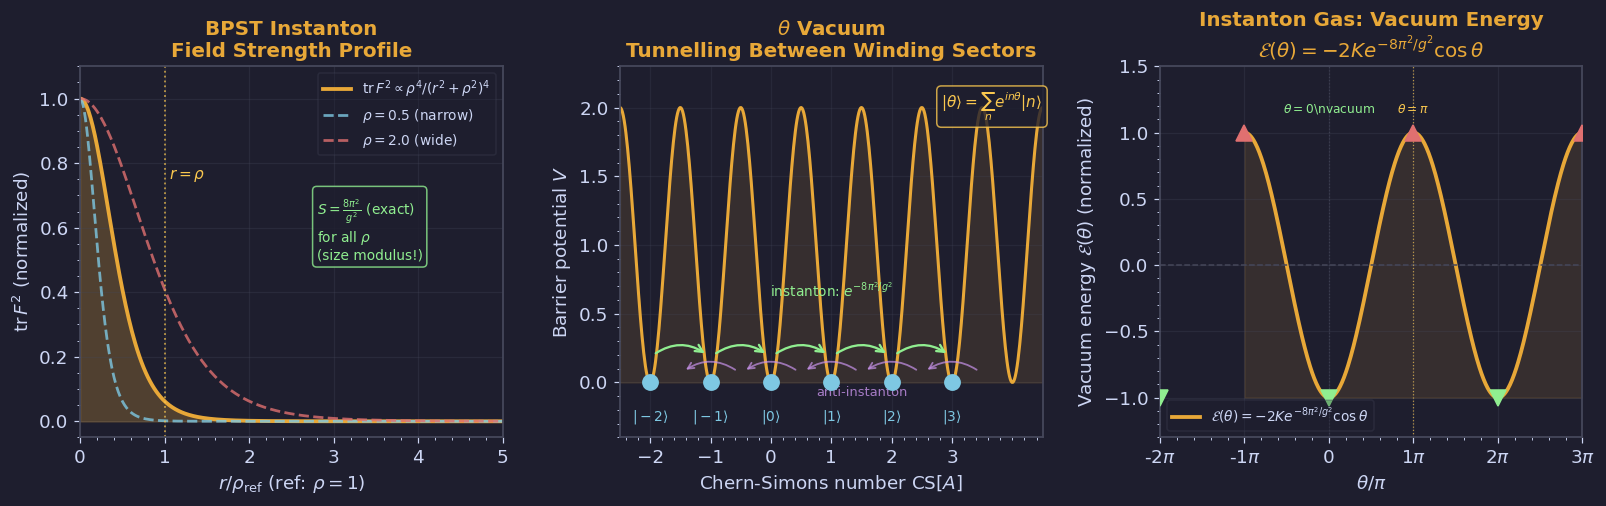

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: BPST field strength profile ─────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

r = np.linspace(0, 5, 400)
rho = 1.0

# tr F^2 = 192 rho^4 / (r^2 + rho^2)^4
trFF = 192 * rho**4 / (r**2 + rho**2)**4
trFF_norm = trFF / trFF.max()

ax.fill_between(r/rho, 0, trFF_norm, color=AMBER, alpha=0.25)
ax.plot(r/rho, trFF_norm, color=AMBER, lw=2.5, label=r'$\mathrm{tr}\,F^2 \propto \rho^4/(r^2+\rho^2)^4$')

# FIX: 공통 r축으로 ρ 의존성 표시 — ρ가 클수록 넓어짐
for rho2, col, lbl in [(0.5, BLUE, r'$\rho=0.5$ (narrow)'), (2.0, RED, r'$\rho=2.0$ (wide)')]:
    trFF2 = 192 * rho2**4 / (r**2 + rho2**2)**4
    # FIX: r 고정 (r/rho2 → r), 피크 높이 개별 정규화로 형태 비교
    ax.plot(r/rho, trFF2/trFF2.max(), color=col, lw=1.8, ls='--', alpha=0.8, label=lbl)

ax.axvline(1.0, color=YELLOW, lw=1.2, ls=':', alpha=0.7)
ax.text(1.05, 0.75, r'$r=\rho$', fontsize=10, color=YELLOW)
ax.set_xlabel(r'$r/\rho_{\rm ref}$ (ref: $\rho=1$)')
ax.set_ylabel(r'$\mathrm{tr}\,F^2$ (normalized)')
ax.set_title('BPST Instanton\nField Strength Profile', color=AMBER)
ax.set_xlim(0, 5); ax.set_ylim(-0.05, 1.1)
ax.legend(fontsize=9, labelcolor=FG)
ax.grid(True, alpha=0.3)

# Action annotation
ax.text(2.8, 0.5, r'$S=\frac{8\pi^2}{g^2}$ (exact)'+"\nfor all $\\rho$\n(size modulus!)",
        fontsize=9, color=GREEN,
        bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=GREEN, alpha=0.8))

# ── Middle: Tunnelling between winding vacua ───────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

# Draw potential wells for each winding sector
x_cs = np.linspace(-2.5, 4.5, 500)
# Periodic potential: V ~ -cos(2pi * CS[A])
V_periodic = 1 - np.cos(2*np.pi * x_cs / 1.0)

ax2.fill_between(x_cs, 0, V_periodic, where=(V_periodic < 2.1),
                  color=AMBER, alpha=0.12)
ax2.plot(x_cs, V_periodic, color=AMBER, lw=2)

# Label the vacua
for n_vac, xp in [(-2, -2.0), (-1, -1.0), (0, 0.0), (1, 1.0), (2, 2.0), (3, 3.0)]:
    ax2.plot(xp, 0, 'o', color=BLUE, ms=10, zorder=5)
    ax2.text(xp, -0.28, f'$|{n_vac}\\rangle$', ha='center', fontsize=9, color=BLUE)

# Instanton 화살표 (→, 위쪽 호)
for xp_start in [-1.5, -0.5, 0.5, 1.5, 2.5]:
    ax2.annotate('', xy=(xp_start+0.45, 0.20), xytext=(xp_start-0.45, 0.20),
                arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.5,
                                connectionstyle='arc3,rad=-0.35', mutation_scale=12))
# Anti-instanton 화살표 (←, 아래쪽 호)
for xp_start in [-1.0, 0.0, 1.0, 2.0, 3.0]:
    ax2.annotate('', xy=(xp_start-0.45, 0.08), xytext=(xp_start+0.45, 0.08),
                arrowprops=dict(arrowstyle='->', color=PURPLE, lw=1.2,
                                connectionstyle='arc3,rad=0.35', mutation_scale=10,
                                alpha=0.7))

# 레이블
ax2.text(1.0, 0.62, r'instanton: $e^{-8\pi^2/g^2}$',
         ha='center', fontsize=9, color=GREEN)
ax2.text(1.5, -0.10, r'anti-instanton', ha='center', fontsize=8.5, color=PURPLE, alpha=0.8)

# Chern-Simons label
ax2.set_xlabel(r'Chern-Simons number $\mathrm{CS}[A]$')
ax2.set_ylabel(r'Barrier potential $V$')
ax2.set_title(r'$\theta$ Vacuum'+"\nTunnelling Between Winding Sectors", color=AMBER)
ax2.set_xlim(-2.5, 4.5); ax2.set_ylim(-0.4, 2.3)
ax2.set_xticks(range(-2, 4))
ax2.grid(True, alpha=0.25)

# Theta vacuum wavefunction sketch
ax2.text(4.5, 2.0, r'$|\theta\rangle = \sum_n e^{in\theta}|n\rangle$',
         ha='right', fontsize=10, color=YELLOW,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=YELLOW, alpha=0.8))

# ── Right: Vacuum energy E(theta) ─────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

theta_arr = np.linspace(-np.pi, 3*np.pi, 500)

# E(theta) = -2K exp(-8pi^2/g^2) cos(theta)
K_factor = 1.0  # normalized
E_vac = -K_factor * np.cos(theta_arr)

ax3.fill_between(theta_arr/np.pi, -1, E_vac, color=AMBER, alpha=0.12)
ax3.plot(theta_arr/np.pi, E_vac, color=AMBER, lw=2.5,
         label=r'$\mathcal{E}(\theta)=-2Ke^{-8\pi^2/g^2}\cos\theta$')

# Mark minima and maxima
theta_min = [0, 2, -2]
theta_max = [1, 3, -1]
for tm in theta_min:
    ax3.plot(tm, -1, 'v', color=GREEN, ms=10, zorder=5)
for tm in theta_max:
    ax3.plot(tm, 1, '^', color=RED, ms=10, zorder=5)

ax3.axhline(0, color=EDGE, lw=1, ls='--')
ax3.axvline(0, color=EDGE, lw=0.8, ls=':', alpha=0.7)
ax3.axvline(1, color=YELLOW, lw=0.8, ls=':', alpha=0.7)
ax3.text(0.0, 1.15, r'$\theta=0$\nvacuum', ha='center', fontsize=8, color=GREEN)
ax3.text(1.0, 1.15, r'$\theta=\pi$', ha='center', fontsize=8, color=YELLOW)

ax3.set_xlabel(r'$\theta/\pi$')
ax3.set_ylabel(r'Vacuum energy $\mathcal{E}(\theta)$ (normalized)')
ax3.set_title(r'Instanton Gas: Vacuum Energy'+"\n"+r'$\mathcal{E}(\theta) = -2Ke^{-8\pi^2/g^2}\cos\theta$',
              color=AMBER)
ax3.set_xlim(-2, 3); ax3.set_ylim(-1.3, 1.5)
ax3.set_xticks(range(-2, 4))
ax3.set_xticklabels([f'{v}$\\pi$' if v != 0 else '0' for v in range(-2, 4)])
ax3.legend(fontsize=9, labelcolor=FG)
ax3.grid(True, alpha=0.3)

plt.tight_layout(pad=1.8)
save('fig02_instanton.png', fig)

---
## fig03 · Running Coupling & Asymptotic Freedom (§2.4)

**Left**: $\alpha_s(\mu)$ vs $\mu$ (log scale) — 1-loop and 2-loop running  
**Middle**: Beta function $\beta(g)$ vs $g$ for different $N_f$  
**Right**: Comparison: QED screening vs QCD anti-screening

  saved -> figures/ch02/fig03_running_coupling.png


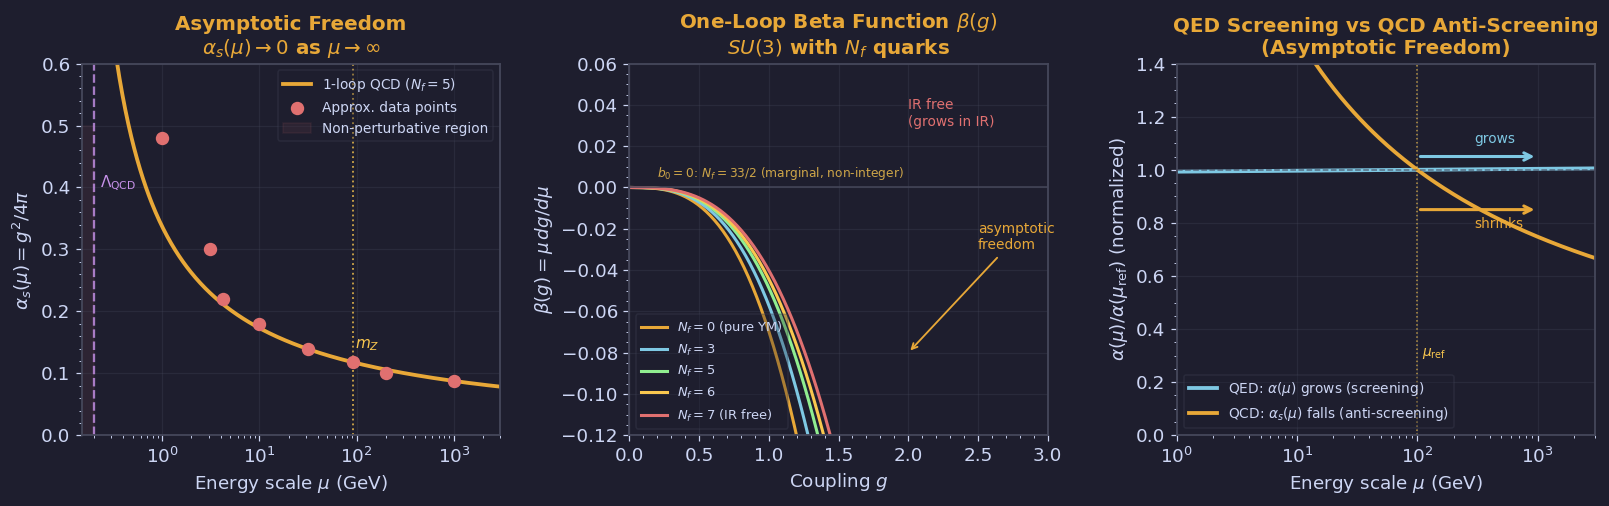

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: Running coupling alpha_s(mu) ────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

# 1-loop running: alpha_s(mu) = alpha_s(mu0) / (1 + b0*alpha_s/(2pi) * ln(mu/mu0))
mu = np.logspace(-1, 4, 500)   # in GeV, from 0.1 to 10000 GeV
mu0 = 91.2  # Z boson mass
alpha_s0 = 0.118  # at mu=mZ
Nc = 3

# b0 = 11/3*Nc - 2/3*Nf; use Nf=5 for mu > mb
Nf = 5
b0 = (11/3)*Nc - (2/3)*Nf
alpha_s_run = alpha_s0 / (1 + b0*alpha_s0/(2*np.pi) * np.log(mu/mu0))
alpha_s_run = np.where(alpha_s_run > 0, alpha_s_run, np.nan)

ax.semilogx(mu, alpha_s_run, color=AMBER, lw=2.5, label=r'1-loop QCD ($N_f=5$)')

# Approximate experimental data points
mu_data = [1.0, 3.1, 4.2, 10.0, 31.6, 91.2, 200.0, 1000.0]
as_data = [0.48, 0.30, 0.22, 0.18, 0.14, 0.118, 0.10, 0.088]
ax.scatter(mu_data, as_data, color=RED, s=60, zorder=5, label='Approx. data points')

# Lambda_QCD marker
Lambda_QCD = 0.2
ax.axvline(Lambda_QCD, color=PURPLE, lw=1.5, ls='--', alpha=0.8)
ax.text(Lambda_QCD*1.15, 0.4, r'$\Lambda_{\rm QCD}$', fontsize=10, color=PURPLE)

# mZ marker
ax.axvline(91.2, color=YELLOW, lw=1.2, ls=':', alpha=0.8)
ax.text(95, 0.14, r'$m_Z$', fontsize=10, color=YELLOW)

ax.fill_between(mu, 0, 0.5, where=(mu < Lambda_QCD),
                color=RED, alpha=0.08, label='Non-perturbative region')

ax.set_xlabel(r'Energy scale $\mu$ (GeV)')
ax.set_ylabel(r'$\alpha_s(\mu) = g^2/4\pi$')
ax.set_title('Asymptotic Freedom\n'+r'$\alpha_s(\mu)\to 0$ as $\mu\to\infty$', color=AMBER)
ax.set_xlim(0.15, 3000); ax.set_ylim(0, 0.6)
ax.legend(fontsize=9, labelcolor=FG)
ax.grid(True, alpha=0.3)

# ── Middle: Beta function vs g ─────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

g_arr = np.linspace(0, 3, 300)

# beta(g) = -g^3/(16pi^2) * b0
for Nf_val, col, lbl in [(0, AMBER, r'$N_f=0$ (pure YM)'),
                           (3, BLUE,  r'$N_f=3$'),
                           (5, GREEN, r'$N_f=5$'),
                           # FIX: Nf=6 marginal 오류. b₀(Nf=6)=7>0 → AF
                           # 실제 marginal(b₀=0): Nf=33/2≈16.5 (비정수)
                           (6, YELLOW, r'$N_f=6$'),
                           (7, RED,    r'$N_f=7$ (IR free)')]:
    b0_val = (11/3)*3 - (2/3)*Nf_val
    beta_val = -g_arr**3 / (16*np.pi**2) * b0_val
    ls = '-' if b0_val > 0 else '--'
    ax2.plot(g_arr, beta_val, color=col, lw=2, ls=ls, label=lbl)

ax2.axhline(0, color=EDGE, lw=1)
ax2.axvline(0, color=EDGE, lw=0.8)

ax2.annotate('asymptotic\nfreedom', xy=(2.0, -0.08), xytext=(2.5, -0.03),
             fontsize=9, color=AMBER,
             arrowprops=dict(arrowstyle='->', color=AMBER, lw=1.2))
ax2.text(2.0, 0.03, 'IR free\n(grows in IR)', fontsize=9, color=RED)
# marginal 경계 주석
ax2.text(0.2, 0.005, r'$b_0=0$: $N_f=33/2$ (marginal, non-integer)',
         fontsize=8, color=YELLOW, alpha=0.8)

ax2.set_xlabel(r'Coupling $g$')
ax2.set_ylabel(r'$\beta(g) = \mu\,dg/d\mu$')
ax2.set_title(r'One-Loop Beta Function $\beta(g)$'+"\n"+r'$SU(3)$ with $N_f$ quarks', color=AMBER)
ax2.set_xlim(0, 3); ax2.set_ylim(-0.12, 0.06)
ax2.legend(fontsize=8.5, labelcolor=FG, loc='lower left')
ax2.grid(True, alpha=0.3)

# ── Right: QED vs QCD screening comparison ────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

mu3 = np.logspace(0, 4, 300)  # GeV
mu3_ref = 100.0

# QED: coupling grows (screening)
alpha_QED_0 = 1/137.0
b0_QED = -2/3  # one charged fermion; beta positive
alpha_QED = alpha_QED_0 / (1 + b0_QED*alpha_QED_0/(np.pi) * np.log(mu3/mu3_ref))
alpha_QED = np.where(alpha_QED > 0, alpha_QED, np.nan)
alpha_QED_norm = alpha_QED / alpha_QED_0

# QCD: coupling decreases (anti-screening)
alpha_QCD_0 = 0.12
b0_QCD_3 = (11/3)*3 - (2/3)*5
alpha_QCD = alpha_QCD_0 / (1 + b0_QCD_3*alpha_QCD_0/(2*np.pi) * np.log(mu3/mu3_ref))
alpha_QCD = np.where(alpha_QCD > 0, alpha_QCD, np.nan)
alpha_QCD_norm = alpha_QCD / alpha_QCD_0

ax3.semilogx(mu3, alpha_QED_norm, color=BLUE, lw=2.5,
             label=r'QED: $\alpha(\mu)$ grows (screening)')
ax3.semilogx(mu3, alpha_QCD_norm, color=AMBER, lw=2.5,
             label=r'QCD: $\alpha_s(\mu)$ falls (anti-screening)')

ax3.axhline(1, color=EDGE, lw=1, ls='--', alpha=0.7)
ax3.axvline(mu3_ref, color=YELLOW, lw=1, ls=':', alpha=0.7)
ax3.text(mu3_ref*1.1, 0.3, r'$\mu_{\rm ref}$', fontsize=9, color=YELLOW)

# Arrows indicating trend
ax3.annotate('', xy=(1000, 1.05), xytext=(100, 1.05),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=2, mutation_scale=12))
ax3.annotate('', xy=(1000, 0.85), xytext=(100, 0.85),
             arrowprops=dict(arrowstyle='->', color=AMBER, lw=2, mutation_scale=12))
ax3.text(300, 1.10, 'grows', fontsize=9, color=BLUE)
ax3.text(300, 0.78, 'shrinks', fontsize=9, color=AMBER)

ax3.set_xlabel(r'Energy scale $\mu$ (GeV)')
ax3.set_ylabel(r'$\alpha(\mu)/\alpha(\mu_{\rm ref})$ (normalized)')
ax3.set_title('QED Screening vs QCD Anti-Screening\n(Asymptotic Freedom)', color=AMBER)
ax3.set_xlim(1, 3000); ax3.set_ylim(0.0, 1.4)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.grid(True, alpha=0.3)

plt.tight_layout(pad=1.8)
save('fig03_running_coupling.png', fig)

---
## fig04 · Confinement & Flux Tube (§2.5)

**Left**: Chromoelectric flux tube between quark-antiquark pair  
**Middle**: $\log\langle W(R,T)\rangle$ vs area — lattice-style data  
**Right**: Dual superconductor schematic — electric vs magnetic condensates

  saved -> figures/ch02/fig04_confinement.png


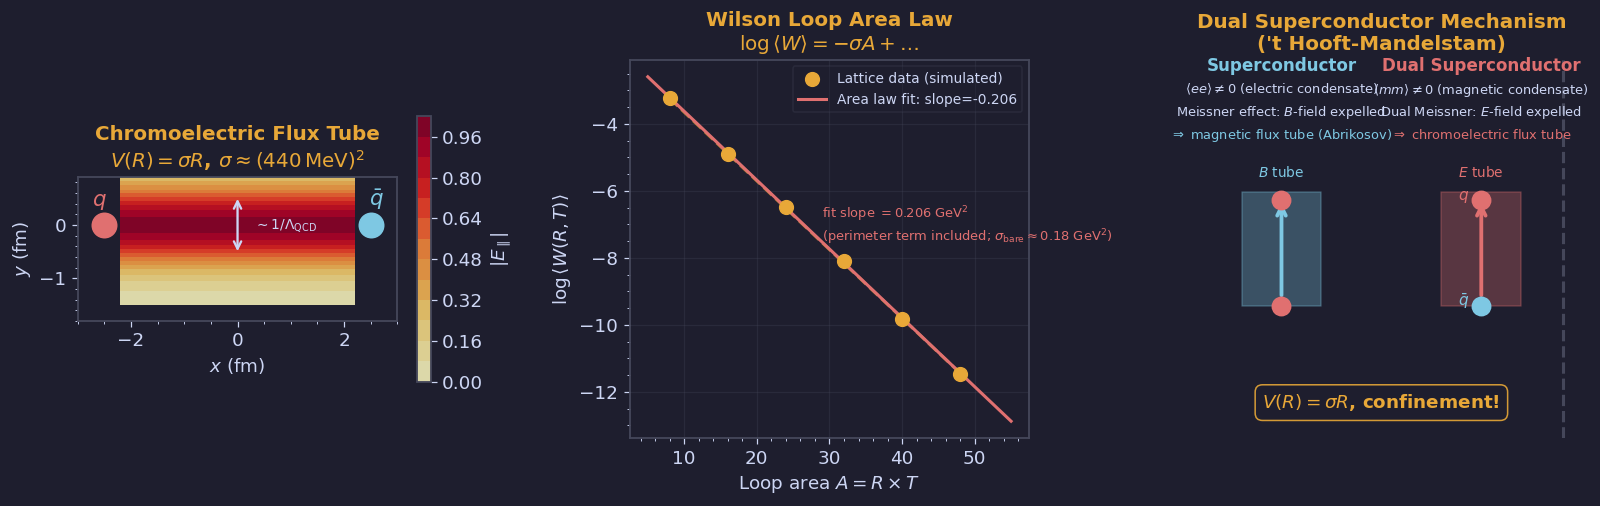

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: Flux tube cross-section ─────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
ax.set_aspect('equal')

# Quark positions
xq, yq = -2.5, 0.0
xqb, yqb = 2.5, 0.0

# Flux tube profile: Gaussian transverse profile
y_perp = np.linspace(-1.5, 1.5, 200)
x_tube = np.linspace(xq+0.3, xqb-0.3, 200)
X_tube, Y_tube = np.meshgrid(x_tube, y_perp)

# Field strength inside tube: E_x(y) ~ exp(-y^2/w^2)
width = 0.55  # tube width in fm
E_field = np.exp(-Y_tube**2 / (2*width**2))

cs = ax.contourf(X_tube, Y_tube, E_field, levels=15, cmap='YlOrRd', alpha=0.85)
plt.colorbar(cs, ax=ax, label=r'$|E_\parallel|$', shrink=0.7)

# Quark/antiquark
ax.plot(xq, yq, 'o', color=RED, ms=16, zorder=5)
ax.text(xq-0.1, yq+0.35, r'$q$', color=RED, fontsize=14, fontweight='bold', ha='center')
ax.plot(xqb, yqb, 'o', color=BLUE, ms=16, zorder=5)
ax.text(xqb+0.1, yqb+0.35, r'$\bar{q}$', color=BLUE, fontsize=14, fontweight='bold', ha='center')

# Width annotation
ax.annotate('', xy=(0, width), xytext=(0, -width),
            arrowprops=dict(arrowstyle='<->', color=FG, lw=1.5))
ax.text(0.3, 0, r'$\sim 1/\Lambda_{\rm QCD}$', fontsize=9, color=FG, va='center')

ax.set_xlim(-3.0, 3.0); ax.set_ylim(-1.8, 0.9)
ax.set_xlabel(r'$x$ (fm)')
ax.set_ylabel(r'$y$ (fm)')
ax.set_title('Chromoelectric Flux Tube\n'+r'$V(R)=\sigma R$, $\sigma\approx(440\,\mathrm{MeV})^2$', color=AMBER)

# ── Middle: Wilson loop area law (lattice-style) ───────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

# Simulate lattice-like data: log<W(R,T)> = -sigma*R*T - alpha*(2R+2T)
np.random.seed(42)
sigma_lat = 0.18  # GeV^2 -> string tension
alpha_per = 0.1   # perimeter coefficient

R_vals = np.array([1, 2, 3, 4, 5, 6])
T_val = 8  # fixed T

log_W = -sigma_lat * R_vals * T_val - alpha_per * (2*R_vals + 2*T_val)
log_W_noisy = log_W + np.random.normal(0, 0.05, len(R_vals))
area_vals = R_vals * T_val

ax2.scatter(area_vals, log_W_noisy, color=AMBER, s=80, zorder=5, label='Lattice data (simulated)')
ax2.plot(area_vals, log_W, color=AMBER, lw=2, ls='--', alpha=0.7)

# Best fit line
fit = np.polyfit(area_vals, log_W_noisy, 1)
fit_line = np.poly1d(fit)
area_fit = np.linspace(5, 55, 100)
ax2.plot(area_fit, fit_line(area_fit), color=RED, lw=2,
         label=f'Area law fit: slope={fit[0]:.3f}')

ax2.set_xlabel(r'Loop area $A = R\times T$')
ax2.set_ylabel(r'$\log\langle W(R,T)\rangle$')
ax2.set_title('Wilson Loop Area Law\n'+r'$\log\langle W\rangle = -\sigma A + \ldots$', color=AMBER)
ax2.legend(fontsize=9, labelcolor=FG)
ax2.grid(True, alpha=0.3)

# String tension annotation
# FIX5: fit slope ≠ 0.18 (perimeter 항 포함); 실제 fit값 사용
ax2.text(29, -7.5,
         f'fit slope $= {abs(fit[0]):.3f}$ GeV$^2$\n'
         r'(perimeter term included; $\sigma_{\rm bare}\approx0.18$ GeV$^2$)',
         fontsize=8.5, color=RED)

# ── Right: Dual superconductor schematic ──────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)
ax3.axis('off')

# Left panel: ordinary superconductor
ax3.text(0.25, 0.97, 'Superconductor', ha='center', fontsize=11,
         color=BLUE, fontweight='bold', transform=ax3.transAxes)
ax3.text(0.25, 0.91, r'$\langle ee\rangle\neq 0$ (electric condensate)', ha='center',
         fontsize=8.5, color=FG, transform=ax3.transAxes)
ax3.text(0.25, 0.85, r'Meissner effect: $B$-field expelled', ha='center',
         fontsize=8.5, color=FG, transform=ax3.transAxes)
ax3.text(0.25, 0.79, r'$\Rightarrow$ magnetic flux tube (Abrikosov)', ha='center',
         fontsize=8.5, color=BLUE, transform=ax3.transAxes)

# Draw B-flux tube
tube_y = np.array([0.35, 0.65])
ax3.fill_betweenx(tube_y, 0.15, 0.35, color=BLUE, alpha=0.3, transform=ax3.transAxes)
ax3.annotate('', xy=(0.25, 0.63), xytext=(0.25, 0.37),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5, mutation_scale=14),
             xycoords='axes fraction', textcoords='axes fraction')
ax3.text(0.25, 0.69, r'$B$ tube', ha='center', fontsize=9, color=BLUE, transform=ax3.transAxes)
ax3.plot([0.25], [0.35], 'o', color=RED, ms=12, transform=ax3.transAxes,
         zorder=5, clip_on=False)
ax3.plot([0.25], [0.63], 'o', color=RED, ms=12, transform=ax3.transAxes,
         zorder=5, clip_on=False)

# Divider
ax3.axvline(0.5, color=EDGE, lw=2, ls='--')

# Right panel: dual superconductor
ax3.text(0.75, 0.97, 'Dual Superconductor', ha='center', fontsize=11,
         color=RED, fontweight='bold', transform=ax3.transAxes)
ax3.text(0.75, 0.91, r'$\langle mm\rangle\neq 0$ (magnetic condensate)', ha='center',
         fontsize=8.5, color=FG, transform=ax3.transAxes)
ax3.text(0.75, 0.85, r'Dual Meissner: $E$-field expelled', ha='center',
         fontsize=8.5, color=FG, transform=ax3.transAxes)
ax3.text(0.75, 0.79, r'$\Rightarrow$ chromoelectric flux tube', ha='center',
         fontsize=8.5, color=RED, transform=ax3.transAxes)

# Draw E-flux tube
ax3.fill_betweenx(tube_y, 0.65, 0.85, color=RED, alpha=0.3, transform=ax3.transAxes)
ax3.annotate('', xy=(0.75, 0.63), xytext=(0.75, 0.37),
             arrowprops=dict(arrowstyle='->', color=RED, lw=2.5, mutation_scale=14),
             xycoords='axes fraction', textcoords='axes fraction')
ax3.text(0.75, 0.69, r'$E$ tube', ha='center', fontsize=9, color=RED, transform=ax3.transAxes)
ax3.plot([0.75], [0.35], 'o', color=BLUE, ms=12, transform=ax3.transAxes,
         zorder=5, clip_on=False)
ax3.text(0.72, 0.35, r'$\bar{q}$', ha='right', fontsize=10, color=BLUE, transform=ax3.transAxes)
ax3.plot([0.75], [0.63], 'o', color=RED, ms=12, transform=ax3.transAxes,
         zorder=5, clip_on=False)
ax3.text(0.72, 0.63, r'$q$', ha='right', fontsize=10, color=RED, transform=ax3.transAxes)

# Bottom formula
ax3.text(0.5, 0.08, r'$V(R) = \sigma R$, confinement!',
         ha='center', fontsize=12, color=AMBER, fontweight='bold',
         transform=ax3.transAxes,
         bbox=dict(boxstyle='round,pad=0.4', facecolor=BG, edgecolor=AMBER, alpha=0.9))

ax3.set_title("Dual Superconductor Mechanism\n('t Hooft-Mandelstam)", color=AMBER)

plt.tight_layout(pad=1.8)
save('fig04_confinement.png', fig)

---
## fig05 · 't Hooft-Polyakov Monopole (§2.7)

**Left**: Hedgehog scalar field $\Phi^a = v h(r)\hat{r}^a$ — radial field lines  
**Middle**: Profile functions $h(r)$ and $K(r)$ — numerical BPS solution  
**Right**: Monopole mass $M/4\pi v$ vs $\lambda/g^2$ (BPS limit at $\lambda=0$)

  saved -> figures/ch02/fig05_thooft_polyakov.png


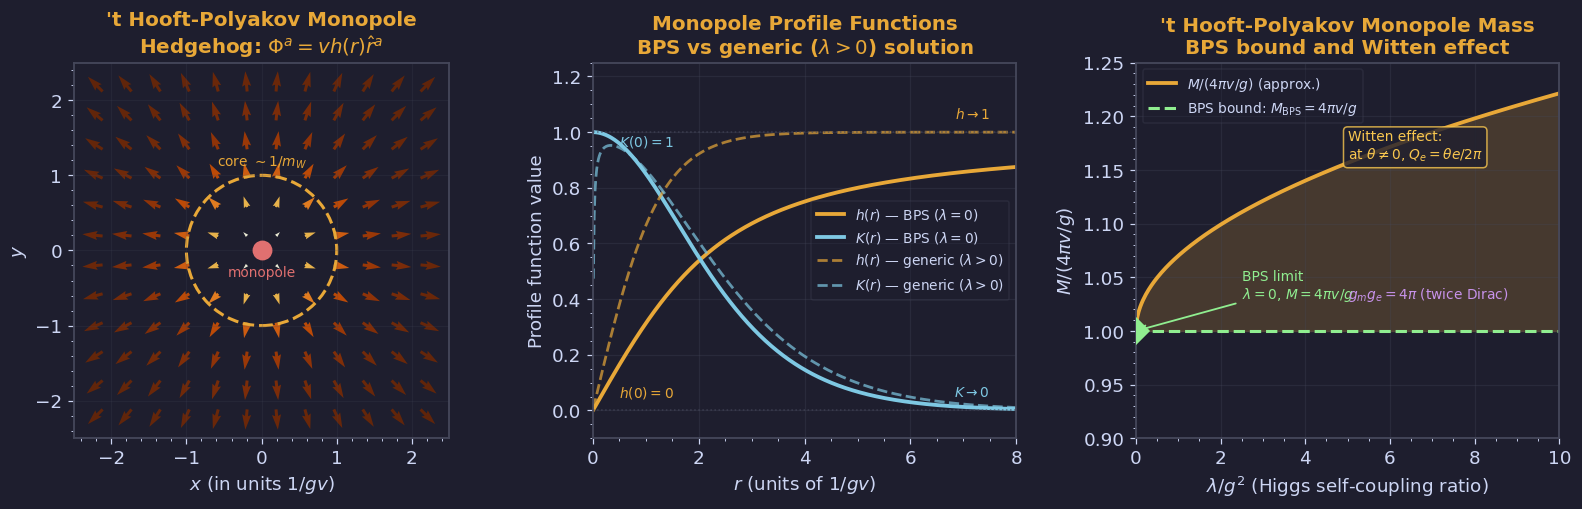

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: Hedgehog field pattern ──────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
ax.set_aspect('equal')

# Hedgehog: Phi^a = h(r) * r_hat^a, so field points radially outward in internal space
x = np.linspace(-2.5, 2.5, 14)
y = np.linspace(-2.5, 2.5, 14)
X, Y = np.meshgrid(x, y)
R_grid = np.sqrt(X**2 + Y**2 + 1e-6)

# Direction: unit radial vector (hedgehog = identity between space and internal space)
Phi_x = X / R_grid
Phi_y = Y / R_grid

# Profile function h(r): 0 at origin, 1 at infinity
h_profile = np.tanh(R_grid)
Phi_x *= h_profile
Phi_y *= h_profile

ax.quiver(X, Y, Phi_x, Phi_y, h_profile,
          cmap='YlOrBr', alpha=0.9, scale=18, width=0.008)

# Core region
core = Circle((0,0), 1.0, fill=False, edgecolor=AMBER, lw=2, ls='--')
ax.add_patch(core)
ax.text(0, 1.12, r'core $\sim 1/m_W$', ha='center', fontsize=9, color=AMBER)

# Origin marker
ax.plot(0, 0, 'o', color=RED, ms=12, zorder=5)
ax.text(0, -0.35, 'monopole', ha='center', fontsize=9, color=RED)

ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5)
ax.set_xlabel(r'$x$ (in units $1/gv$)')
ax.set_ylabel(r'$y$')
ax.set_title("'t Hooft-Polyakov Monopole\n"+r'Hedgehog: $\Phi^a = vh(r)\hat{r}^a$', color=AMBER)
ax.grid(True, alpha=0.2)

# ── Middle: Profile functions h(r) and K(r) ───────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

r_arr = np.linspace(0.01, 8, 500)

# BPS (lambda=0) analytic solutions (Prasad-Sommerfield):
# h(r) = coth(r) - 1/r
# K(r) = r/sinh(r)
h_bps = 1/np.tanh(r_arr) - 1/r_arr
K_bps = r_arr / np.sinh(r_arr)

# Generic (lambda>0): approximate with tanh profile
h_gen = np.tanh(r_arr * 0.8)
K_gen = (r_arr * 0.9) / np.sinh(r_arr * 0.9 + 0.01)

ax2.plot(r_arr, h_bps, color=AMBER, lw=2.5, label=r'$h(r)$ — BPS ($\lambda=0$)')
ax2.plot(r_arr, K_bps, color=BLUE,  lw=2.5, label=r'$K(r)$ — BPS ($\lambda=0$)')
ax2.plot(r_arr, h_gen, color=AMBER, lw=1.8, ls='--', alpha=0.7,
         label=r'$h(r)$ — generic ($\lambda>0$)')
ax2.plot(r_arr, K_gen, color=BLUE,  lw=1.8, ls='--', alpha=0.7,
         label=r'$K(r)$ — generic ($\lambda>0$)')

# Asymptotic values
ax2.axhline(1, color=EDGE, lw=1, ls=':', alpha=0.7)
ax2.axhline(0, color=EDGE, lw=1, ls=':', alpha=0.7)

# Boundary condition labels
ax2.text(7.5, 1.05, r'$h\to 1$', fontsize=9, color=AMBER, ha='right')
ax2.text(7.5, 0.05, r'$K\to 0$', fontsize=9, color=BLUE, ha='right')
ax2.text(0.5, 0.05, r'$h(0)=0$', fontsize=9, color=AMBER)
ax2.text(0.5, 0.95, r'$K(0)=1$', fontsize=9, color=BLUE)

ax2.set_xlabel(r'$r$ (units of $1/gv$)')
ax2.set_ylabel('Profile function value')
ax2.set_title('Monopole Profile Functions\n'+r'BPS vs generic ($\lambda>0$) solution', color=AMBER)
ax2.set_xlim(0, 8); ax2.set_ylim(-0.1, 1.25)
ax2.legend(fontsize=9, labelcolor=FG)
ax2.grid(True, alpha=0.3)

# ── Right: Monopole mass vs lambda/g^2 ────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

# M/(4pi v/g) vs lambda/g^2
# BPS limit: M = 4pi v/g (lambda=0)
# For lambda>0: M > 4pi v/g (monotonically increasing)
# Simple fit: M/M_BPS ~ 1 + 0.07*sqrt(lambda/g^2)
lam_g2 = np.linspace(0, 10, 300)
M_ratio = 1.0 + 0.07 * np.sqrt(lam_g2)  # approximate

ax3.fill_between(lam_g2, 1.0, M_ratio, color=AMBER, alpha=0.2)
ax3.plot(lam_g2, M_ratio, color=AMBER, lw=2.5, label=r'$M/(4\pi v/g)$ (approx.)')
ax3.axhline(1.0, color=GREEN, lw=2, ls='--', label=r'BPS bound: $M_{\rm BPS} = 4\pi v/g$')

# BPS point
ax3.plot(0, 1.0, 'D', color=GREEN, ms=12, zorder=5)
ax3.annotate('BPS limit\n'+r'$\lambda=0$, $M=4\pi v/g$',
             xy=(0, 1.0), xytext=(2.5, 1.03),
             fontsize=9, color=GREEN,
             arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.2))

# Witten effect annotation
ax3.text(5, 1.16,
         'Witten effect:\n'+r'at $\theta\neq 0$, $Q_e = \theta e/2\pi$',
         fontsize=9, color=YELLOW,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=YELLOW, alpha=0.8))

# Dirac charge relation
ax3.text(5, 1.03,
         r'$g_m g_e = 4\pi$ (twice Dirac)',
         fontsize=9, color=PURPLE)

ax3.set_xlabel(r'$\lambda/g^2$ (Higgs self-coupling ratio)')
ax3.set_ylabel(r'$M / (4\pi v/g)$')
ax3.set_title("'t Hooft-Polyakov Monopole Mass\nBPS bound and Witten effect", color=AMBER)
ax3.set_xlim(0, 10); ax3.set_ylim(0.9, 1.25)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.grid(True, alpha=0.3)

plt.tight_layout(pad=1.8)
save('fig05_thooft_polyakov.png', fig)

---
## Download figures

Run this cell after all figures are generated to download as a zip file.

In [7]:
import shutil
from google.colab import files

shutil.make_archive('gauge_ch02_figures', 'zip', '.', 'figures')
files.download('gauge_ch02_figures.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Checklist

| File | Content | Status |
|------|---------|--------|
| `fig01_wilson_loop.png`     | Wilson loop schematic / area vs perimeter / quark potential | ☐ |
| `fig02_instanton.png`       | BPST profile / tunnelling / vacuum energy $\mathcal{E}(\theta)$ | ☐ |
| `fig03_running_coupling.png`| $\alpha_s(\mu)$ / beta function / QED vs QCD | ☐ |
| `fig04_confinement.png`     | Flux tube / Wilson area law / dual superconductor | ☐ |
| `fig05_thooft_polyakov.png` | Hedgehog / profile $h,K$ / mass vs $\lambda/g^2$ | ☐ |